In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
adv=pd.read_csv("Advertising.csv")
adv1=adv.iloc[:,:4]
adv1

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


## BASIC CHECKS

In [3]:
adv1.shape

(200, 4)

In [4]:
adv1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
adv1.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [6]:
adv1.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [7]:
adv1.tail()

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


## EDA

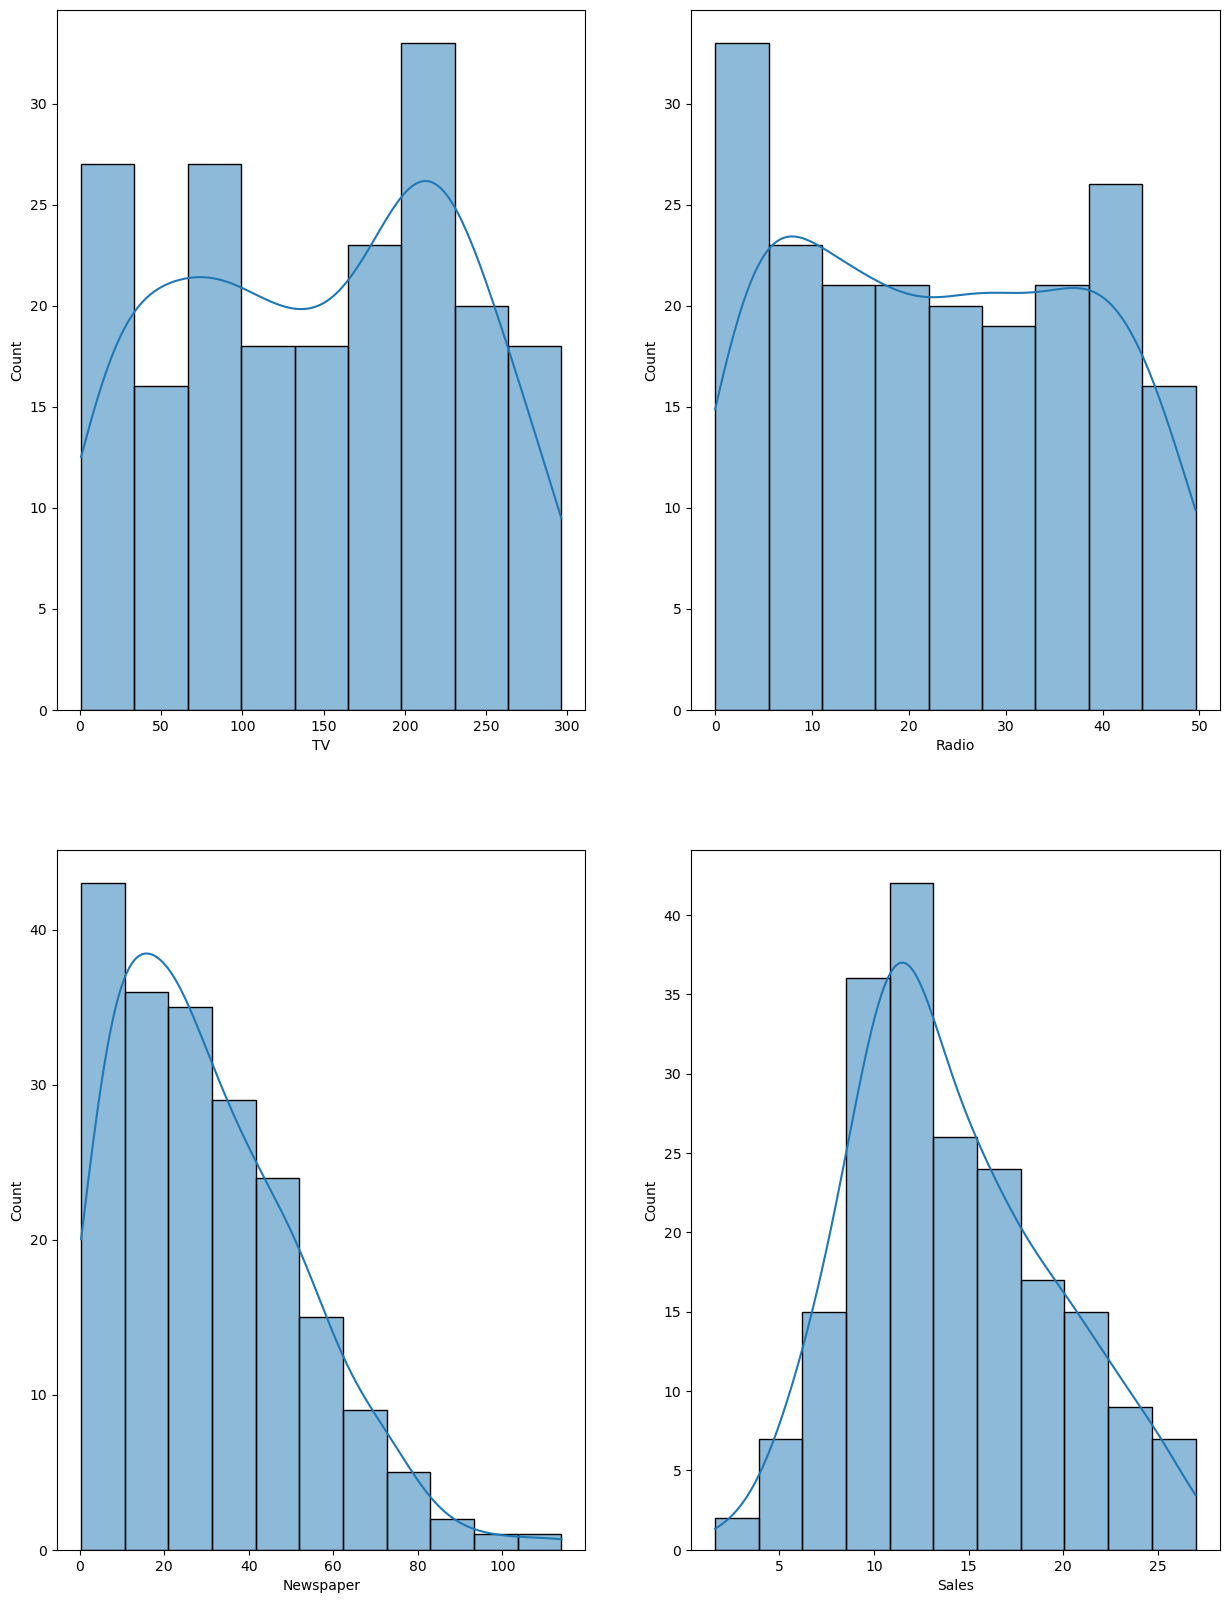

In [8]:
plt.figure(figsize=(15,20),facecolor='white')
pltsize=1
for i in adv1.columns:
    plt.subplot(2,2,pltsize)
    sns.histplot(adv1[i],kde=True)
    pltsize+=1
plt.show()

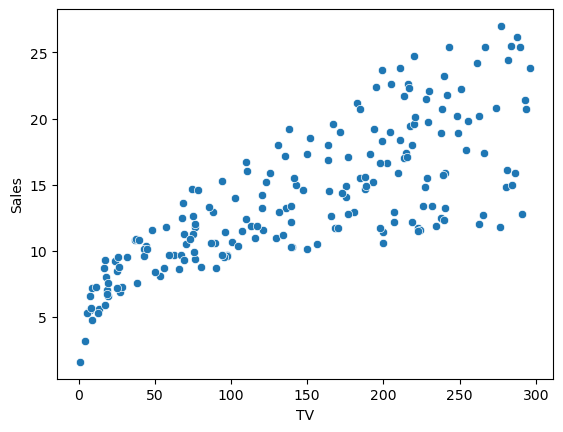

In [9]:
sns.scatterplot(x='TV',y='Sales',data=adv1)
plt.show()

## Data Preprocessing and feature selection

In [10]:
adv1.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [11]:
adv1.duplicated().sum()

0

In [12]:
adv1['Radio']=adv1['Radio'].replace(0,adv1['Radio'].mean())
adv1

C:\Users\rmrar\AppData\Local\Temp\ipykernel_3152\3695855432.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adv1['Radio']=adv1['Radio'].replace(0,adv1['Radio'].mean())


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [13]:
adv1.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.380320,30.554000,14.022500
std,85.854236,14.754473,21.778621,5.217457
min,0.700000,0.300000,0.300000,1.600000
25%,74.375000,10.075000,12.750000,10.375000
50%,149.750000,23.282000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [14]:
x=adv1[adv1.columns[:-1]].corr()
x

,TV,Radio,Newspaper
TV,1.000000,0.048983,0.056648
Radio,0.048983,1.000000,0.348551
Newspaper,0.056648,0.348551,1.000000


In [15]:
x[x>0.8]


,TV,Radio,Newspaper
TV,1.0,NaN,NaN
Radio,NaN,1.0,NaN
Newspaper,NaN,NaN,1.0


In [16]:
from sklearn.preprocessing import MinMaxScaler
sc=MinMaxScaler()
data1=sc.fit_transform(adv1)
data1



array([[0.77578627, 0.76064909, 0.60598065, 0.80708661],
       [0.1481231 , 0.79107505, 0.39401935, 0.34645669],
       [0.0557998 , 0.92494929, 0.60686016, 0.30314961],
       [0.50997633, 0.831643  , 0.51187335, 0.66535433],
       [0.60906324, 0.21298174, 0.51099384, 0.44488189],
       [0.02705445, 0.98580122, 0.65699208, 0.22047244],
       [0.19208657, 0.65922921, 0.20404573, 0.4015748 ],
       [0.4041258 , 0.39148073, 0.09938434, 0.45669291],
       [0.02671627, 0.03651116, 0.00615655, 0.12598425],
       [0.67331755, 0.04665314, 0.18381706, 0.35433071],
       [0.2211701 , 0.11156187, 0.21020229, 0.27559055],
       [0.72370646, 0.48073022, 0.03254178, 0.62204724],
       [0.07811972, 0.70588235, 0.5769569 , 0.2992126 ],
       [0.32735881, 0.14807302, 0.06068602, 0.31889764],
       [0.68785932, 0.66125761, 0.40193492, 0.68503937],
       [0.65843761, 0.96146045, 0.46262093, 0.81889764],
       [0.22691917, 0.73630832, 1.        , 0.42913386],
       [0.94927291, 0.79716024,

In [17]:
res=pd.DataFrame(data=data1,columns=adv1.columns)
res

,TV,Radio,Newspaper,Sales
0,0.775786,0.760649,0.605981,0.807087
1,0.148123,0.791075,0.394019,0.346457
2,0.055800,0.924949,0.606860,0.303150
3,0.509976,0.831643,0.511873,0.665354
4,0.609063,0.212982,0.510994,0.444882
...,...,...,...,...
195,0.126818,0.068966,0.118734,0.236220
196,0.316199,0.093306,0.068602,0.318898
197,0.596212,0.182556,0.053650,0.440945
198,0.956713,0.845842,0.579595,0.940945


<Axes: >

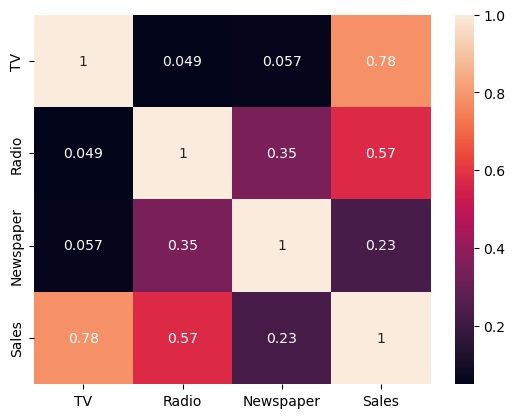

In [18]:
sns.heatmap(res.corr(),annot=True)

## Model Creation

In [19]:
X=res.iloc[:,:-1]
X

,TV,Radio,Newspaper
0,0.775786,0.760649,0.605981
1,0.148123,0.791075,0.394019
2,0.055800,0.924949,0.606860
3,0.509976,0.831643,0.511873
4,0.609063,0.212982,0.510994
...,...,...,...
195,0.126818,0.068966,0.118734
196,0.316199,0.093306,0.068602
197,0.596212,0.182556,0.053650
198,0.956713,0.845842,0.579595


In [20]:
y=res['Sales']
y

0      0.807087
1      0.346457
2      0.303150
3      0.665354
4      0.444882
         ...   
195    0.236220
196    0.318898
197    0.440945
198    0.940945
199    0.464567
Name: Sales, Length: 200, dtype: float64

In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.80,random_state=42)


In [22]:
from sklearn.linear_model import LinearRegression
li=LinearRegression()
li.fit(X_train,y_train)

LinearRegression()

In [23]:
y_pred=li.predict(X_test)

In [24]:
y_test

95     0.602362
15     0.818898
30     0.779528
158    0.224409
128    0.909449
         ...   
59     0.661417
171    0.507874
131    0.437008
17     0.897638
72     0.283465
Name: Sales, Length: 160, dtype: float64

In [25]:
y_pred

array([0.59983604, 0.77100681, 0.80894362, 0.34009421, 0.76160779,
       0.45651809, 0.75150579, 0.20333097, 0.46531161, 0.53146213,
       0.23644632, 0.1893457 , 0.58236192, 0.23307369, 0.31770801,
       0.42609143, 0.26634367, 0.55667651, 0.32936309, 0.65641836,
       0.75753911, 0.53429042, 0.36931459, 0.82427277, 0.20038213,
       0.14792579, 0.74776955, 0.38096643, 0.28474837, 0.21059236,
       0.4278189 , 0.30056768, 0.7986194 , 0.45470367, 0.67885099,
       0.69715283, 0.43030877, 0.79852217, 0.33433522, 0.09520203,
       0.30724116, 0.41138045, 0.31599327, 0.2332767 , 0.46474576,
       0.12075001, 0.30186164, 0.47233314, 0.28684145, 0.35903069,
       0.51951552, 0.38845065, 0.45603279, 0.35357174, 0.17421585,
       0.32955958, 0.27735132, 0.90959745, 0.20252777, 0.40974532,
       0.62276141, 0.5271637 , 0.38839875, 0.37775996, 0.5929419 ,
       0.18094847, 0.75173898, 0.15428059, 0.30439877, 0.33357116,
       0.26523563, 0.32835231, 0.51857538, 0.61939047, 0.59986

In [26]:
X_test

,TV,Radio,Newspaper
95,0.549882,0.634888,0.462621
15,0.658438,0.961460,0.462621
30,0.988164,0.567951,0.377309
158,0.037200,0.742394,0.394899
128,0.742645,0.987830,0.025506
...,...,...,...
59,0.710179,0.592292,0.079156
171,0.553940,0.417850,0.414248
131,0.894488,0.052738,0.375550
17,0.949273,0.797160,0.488127


In [27]:
from sklearn.metrics import *
import math
r2=r2_score(y_test,y_pred)
r2

0.8775188765852566

In [28]:
mse=mean_squared_error(y_pred,y_test)
mse

0.005100808122854379

In [29]:
mae=mean_absolute_error(y_pred,y_test)
mae

0.05766440208017094

In [30]:
from sklearn.metrics import *
import math
print(mean_squared_error(y_test,y_pred))
print(math.sqrt(mean_squared_error(y_test,y_pred)))

0.005100808122854379
0.0714199420530035


In [32]:
print(np.sqrt(mse))

0.0714199420530035
